# S1 CW 26/27 - Solution

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
import toy

SEED = 67
plt.style.use('yl.mplstyle')

results = {}

In [2]:
%config InlineBackend.figure_format = 'svg'

## **Q1** -- A first measurement of the data

### 1a) Fitting the observed dataset

In [3]:
from iminuit import Minuit

data = toy.observed()

In [4]:
data

array([[-0.05714585,  0.0147172 ,  0.05002457,  0.07962564],
       [ 0.12315868, -0.21759146, -0.1246618 , -0.08952672],
       [-0.17119047, -0.01651206,  0.16810725,  0.14919557]])

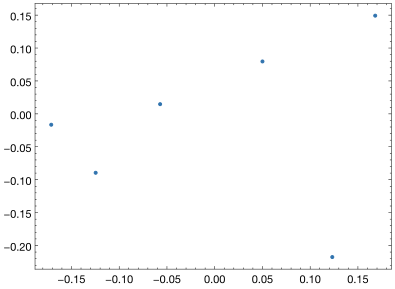

In [5]:
# i don't know what the data looks like, so i plot it 
plt.scatter(data[:, ::2], data[:, 1::2])

i want to see where each channels are and how the covariance matrix provided can help with understanding the data i am working with.

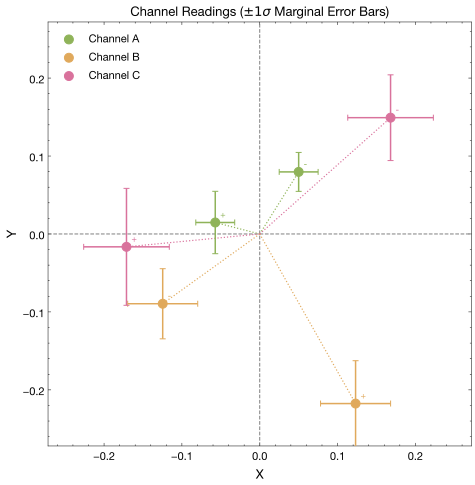

In [6]:
channels = ["A", "B", "C"]
colours = ["C1", "C2", "C3"]

fig, ax = plt.subplots(figsize=(7,7))
# plot grey lines for x=0 and y=0 
ax.axhline(0, color="grey", ls="--", lw=1)
ax.axvline(0, color="grey", ls="--", lw=1)

for i, (ch, colour) in enumerate(zip(channels, colours)):
  xs = data[i, ::2]
  ys = data[i, 1::2]
  ax.scatter(xs, ys, color=colour, label=f"Channel {ch}", s=80, zorder=4)

  # plot error bars from covariance matrix 
  cov = toy.covariance(ch)
  stds = np.sqrt(np.diag(cov))
  x_errs, y_errs = stds[::2], stds[1::2]

  for sign, x, y, xerr, yerr in zip(["+", "-"], xs, ys, x_errs, y_errs):
    ax.plot([0, x], [0, y], color=colour, ls=":", lw=1.2)
    ax.annotate(sign, (x, y), xytext=(5, 5), textcoords="offset points", fontsize=9, color=colour)
    if xerr is not None:
      ax.errorbar(x, y, xerr=xerr, yerr=yerr, fmt="none", ecolor=colour, elinewidth=1.5, capsize=3, zorder=3)

limit = np.max(np.abs(data)) * 1.25
ax.set(xlim=(-limit, limit), ylim=(-limit, limit), aspect="equal",
       xlabel="X", ylabel="Y", title=r"Channel Readings ($\pm1\sigma$ Marginal Error Bars)")
ax.legend()

plt.tight_layout()
plt.show()

TODO: show working

In [20]:
V_i = np.array([toy.covariance(f'{channel}') for channel in channels]) # shape: (3, 4, 4)
V_i_inv = np.linalg.inv(V_i)
V_i_inv

array([[[1616.16161616,  101.01010101,    0.        ,    0.        ],
        [ 101.01010101,  631.31313131,    0.        ,    0.        ],
        [   0.        ,    0.        , 1666.66666667,  333.33333333],
        [   0.        ,    0.        ,  333.33333333, 1666.66666667]],

       [[ 498.81531363,  -40.81216202,    0.        ,    0.        ],
        [ -40.81216202,  333.91768929,    0.        ,    0.        ],
        [   0.        ,    0.        ,  498.81531363,   49.88153136],
        [   0.        ,    0.        ,   49.88153136,  498.81531363]],

       [[ 331.40702997,  -12.1515911 ,    0.        ,    0.        ],
        [ -12.1515911 ,  178.22333612,    0.        ,    0.        ],
        [   0.        ,    0.        ,  333.91768929,   33.39176893],
        [   0.        ,    0.        ,   33.39176893,  333.91768929]]])

In [39]:
def mu_i(r_i, delta_i, gamma):
    return (r_i*(np.cos(delta_i + gamma)), r_i*(np.sin(delta_i + gamma)), r_i*(np.cos(delta_i - gamma)), r_i*(np.sin(delta_i - gamma)))

def model_chi2(gamma, r_A, r_B, r_C, delta_A, delta_B, delta_C):
    rs = [r_A, r_B, r_C]
    deltas = [delta_A, delta_B, delta_C]
    chi2_total = 0
    
    for i in range(3):
        r_i = rs[i]
        delta_i = deltas[i]
        
        # X_i - mu_i
        d = data[i] - mu_i(r_i, delta_i, gamma)
        chi2_total += d @ V_i_inv[i] @ d
        
    return chi2_total

initial guesses:

looking at geometry, i will take initial guess of:
- r_i as the average of the 2 rs
    - $r_i = \frac{1}{2}\left(\sqrt{(x_i^+)^2 + (y_i^+)^2} + \sqrt{(x_i^-)^2 + (y_i^-)^2}\right)$

- delta_i as the arctan2 of the sum of the vectors
    - $\delta_i = \mathrm{arctan2}( y_i^+ + y_i^- , x_i^+ + x_i^- )$

- gamma as the half difference of the positive points and the negative points

In [26]:
r_init = []
delta_init = []
gamma_guesses = []

for i in range(3):
    xp, yp, xm, ym = data[i]
    r_init.append(0.5 * (np.hypot(xp, yp) + np.hypot(xm, ym)))
    delta_init.append(np.arctan2(yp + ym, xp + xm))
    ang_p = np.arctan2(yp, xp)
    ang_m = np.arctan2(ym, xm)
    # Half-difference wrapped to [-pi, pi]
    diff_ang = np.angle(np.exp(1j * (ang_p - ang_m)))
    gamma_guesses.append(0.5 * diff_ang)

gamma_init = float(np.mean(gamma_guesses))

In [47]:
mi = Minuit(
    fcn=model_chi2,
    gamma=gamma_init,
    r_A=r_init[0], r_B=r_init[1], r_C=r_init[2],
    delta_A=delta_init[0], delta_B=delta_init[1], delta_C=delta_init[2],
)
mi.errordef = Minuit.LEAST_SQUARES  # Crucial: tells Minuit this is a chi^2 (Delta chi^2 = 1)
mi.limits['r_A'] = (0, None)        # Amplitudes are r_i >= 0
mi.limits['r_B'] = (0, None)
mi.limits['r_C'] = (0, None)

mi.migrad()  # Finds the minimum
mi.hesse()   # Computes parabolic (HESSE) uncertainties

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 6.174                      │              Nfcn = 193              │
│ EDM = 5.13e-06 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬─────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name    │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼─────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ gamma   │   0.91    │   0.14    │            │            │         │         │       │
│ 1 │ r_A     │   0.080   │   0.017   │            │            │    0    │         │       │
│ 2 │ r_B     │   0.191   │   0.033   │            │            │    0    │         │       │
│ 3 │ r_C     │   0.19    │   0.04    │            │            │    0    │         │       │
│ 4 │ delta_A │   1.88    │   0.28    │            │            │         │         │       │
│ 5 │ delta_B │   -1.80   │   0.18    │            │            │         │         │       │
│ 6 │ delta_C │   1.84    │   0.24    │            │            │         │         │       │
└───┴─────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌─────────┬────────────────────────────────────────────────────────────────┐
│         │    gamma      r_A      r_B      r_C  delta_A  delta_B  delta_C │
├─────────┼────────────────────────────────────────────────────────────────┤
│   gamma │   0.0192 -0.34e-3  -0.0006   0.0004    0.012   -0.003    0.008 │
│     r_A │ -0.34e-3 0.000302  0.01e-3 -0.01e-3 -0.68e-3  0.05e-3 -0.14e-3 │
│     r_B │  -0.0006  0.01e-3  0.00106  -0.0000  -0.0004  -0.0007  -0.0003 │
│     r_C │   0.0004 -0.01e-3  -0.0000  0.00148   0.0002  -0.0001  -0.0004 │
│ delta_A │    0.012 -0.68e-3  -0.0004   0.0002   0.0807   -0.002     0.00 │
│ delta_B │   -0.003  0.05e-3  -0.0007  -0.0001   -0.002   0.0332   -0.001 │
│ delta_C │    0.008 -0.14e-3  -0.0003  -0.0004     0.00   -0.001   0.0571 │
└─────────┴────────────────────────────────────────────────────────────────┘

In [64]:
from scipy.stats import chi2
chi2_min = mi.fval
p_val = float(chi2.sf(chi2_min, df=5))

In [65]:
results['1a'] = {
    'gamma':mi.values['gamma'],
    'sigma_gamma': mi.errors['gamma'],
    'chi2': chi2_min,
    'ndof': 5,
    'p-value': p_val
}

In [69]:
results['1a']

{'gamma': 0.9149282422875626,
 'sigma_gamma': 0.13845503970194467,
 'chi2': 6.174445849789934,
 'ndof': 5,
 'p-value': 0.2896128159833423}

### 1b) Plot the geometry

In [ ]:
mi.values['gamma']
mi.values[f'delta_{channel}']
mi.values[f'r_{channel}']

1.8823526692217527

In [106]:
from scipy.stats import chi2, multivariate_normal

def plot_channel(channel, confidence=0.683):
    idx = channels.index(channel)
    colour = colours[idx]
    
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.axhline(0, color="grey", ls="--", lw=1)
    ax.axvline(0, color="grey", ls="--", lw=1)

    xs = data[idx, ::2]
    ys = data[idx, 1::2]
    ax.scatter(xs, ys, color=colour, label=f"Channel {channel}", s=40)

    limit = np.max(np.abs(data[idx])) * 1.6
    grid = np.linspace(-limit, limit, 200)
    X, Y = np.meshgrid(grid, grid)
    pos = np.dstack((X, Y))

    # Critical chi-squared value (df=2) for the target 2D confidence level
    k = chi2.ppf(confidence, df=2)

    cov = toy.covariance(channel)
    sub_covs = [cov[:2, :2], cov[2:, 2:]] if cov is not None else [None, None]

    for sign, x, y, sub_cov in zip(["+", "-"], xs, ys, sub_covs):
        ax.plot([0, x], [0, y], color=colour, ls=":", lw=1.2)
        ax.annotate(sign, (x, y), xytext=(5, 5), textcoords="offset points", fontsize=9, color=colour)
        
        if sub_cov is not None:
            rv = multivariate_normal(mean=[x, y], cov=sub_cov)
            level = rv.pdf([x, y]) * np.exp(-0.5 * k)
            ax.contour(X, Y, rv.pdf(pos), levels=[level], colors=[colour], linewidths=1.5)

    ax.set(xlim=(-limit, limit), ylim=(-limit, limit), aspect="equal",
           xlabel="X", ylabel="Y", title=f"Channel {channel} ({confidence:.1%} Confidence Contours)")

    plt.tight_layout()
    fig.savefig(f"results/channel{channel}.pdf")
    plt.show()

In [132]:
import matplotlib.patheffects as pe
from matplotlib.patches import Arc
from scipy.stats import chi2, multivariate_normal


def _place_text(ax, x, y, text, color, fontsize=9, fontweight="normal", ha="center", va="center"):
    txt = ax.text(
        x, y, text,
        color=color,
        fontsize=fontsize,
        fontweight=fontweight,
        ha=ha,
        va=va,
        zorder=10,
    )
    txt.set_path_effects([pe.withStroke(linewidth=3, foreground="white", alpha=0.9)])
    return txt


def plot_channel(channel, confidence=0.683):
    idx = channels.index(channel)
    colour = colours[idx]

    # Fitted parameters (estimators) for this channel and shared gamma
    gamma = mi.values["gamma"]
    delta = mi.values[f"delta_{channel}"]
    r = mi.values[f"r_{channel}"]

    # Fitted model coordinates from Eq. (3): (x±, y±) = r * (cos(delta ± gamma), sin(delta ± gamma))
    fit_xp, fit_yp = r * np.cos(delta + gamma), r * np.sin(delta + gamma)
    fit_xm, fit_ym = r * np.cos(delta - gamma), r * np.sin(delta - gamma)
    fit_bx, fit_by = r * np.cos(delta), r * np.sin(delta)  # bisector

    # Measured data coordinates
    xs = data[idx, ::2]
    ys = data[idx, 1::2]

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.axhline(0, color="grey", ls="--", lw=0.8, alpha=0.6, zorder=1)
    ax.axvline(0, color="grey", ls="--", lw=0.8, alpha=0.6, zorder=1)

    max_coord = max(np.max(np.abs(data[idx])), r)
    limit = max_coord * 1.6

    grid = np.linspace(-limit, limit, 200)
    X, Y = np.meshgrid(grid, grid)
    pos = np.dstack((X, Y))
    k = chi2.ppf(confidence, df=2)

    cov = toy.covariance(channel)
    sub_covs = [cov[:2, :2], cov[2:, 2:]]

    # 1. Measured points (+ / -) & 68.3% uncertainty contours
    ax.scatter(xs, ys, color=colour, s=40, zorder=4, label="Observed ($\\pm$)")
    for sign, (x, y), sub_cov in zip(["+", "-"], zip(xs, ys), sub_covs):
        rv = multivariate_normal(mean=[x, y], cov=sub_cov)
        level = rv.pdf([x, y]) * np.exp(-0.5 * k)
        ax.contour(
            X, Y, rv.pdf(pos),
            levels=[level],
            colors=[colour],
            linewidths=1.2,
            alpha=0.8,
            zorder=2,
        )
        # Offset slightly radially outward from origin so it clears the marker & contour
        rad = np.hypot(x, y) or 1.0
        ux, uy = x / rad, y / rad
        pad = 0.08 * limit
        _place_text(ax, x + pad * ux, y + pad * uy, sign, color=colour, fontsize=9.5, fontweight="bold")

    # 2. Fitted amplitude circle of radius \hat{r}_i
    circle = plt.Circle(
        (0, 0), r, fill=False, ls=":", lw=1.2, color="grey", alpha=0.7, zorder=2,
        label=f"Fitted radius $\\hat{{r}}_{{{channel}}}$"
    )
    ax.add_patch(circle)
    r_label_angle = delta + np.pi
    _place_text(
        ax,
        r * np.cos(r_label_angle),
        r * np.sin(r_label_angle),
        f"$\\hat{{r}}_{{{channel}}}$",
        color="grey",
        fontsize=9,
        fontweight="bold",
    )

    # 3. Bisector ray at angle \hat{\delta}_i
    ax.plot(
        [0, fit_bx], [0, fit_by], ls="-.", lw=1.3, color="grey", zorder=3,
        label=f"Fitted bisector $\\hat{{\\delta}}_{{{channel}}}$"
    )

    # 4. Fitted model points (+ / -) at (\hat{\delta}_i ± \hat{\gamma}) and rays from origin
    fit_xs = [fit_xp, fit_xm]
    fit_ys = [fit_yp, fit_ym]
    ax.scatter(fit_xs, fit_ys, marker="D", s=40, color="grey", zorder=5, label="Fitted ($\\pm$)")

    for sign, fx, fy in zip(["+", "-"], fit_xs, fit_ys):
        ax.plot([0, fx], [0, fy], ls="-", lw=1.3, color="grey", alpha=0.85, zorder=3)
        rad = np.hypot(fx, fy) or 1.0
        ux, uy = fx / rad, fy / rad
        pad = 0.08 * limit
        _place_text(ax, fx + pad * ux, fy + pad * uy, sign, color="dimgrey", fontsize=9.5, fontweight="bold")

    # 5a. Grey arc for bisector angle \hat{\delta}_i from positive x-axis (0 deg)
    delta_arc_r = 0.25 * r if r > 0 else 0.08
    delta_deg = np.degrees(delta)
    arc_delta = Arc(
        (0, 0),
        width=2 * delta_arc_r,
        height=2 * delta_arc_r,
        angle=0,
        theta1=min(0.0, delta_deg),
        theta2=max(0.0, delta_deg),
        color="grey",
        lw=1.3,
        zorder=3,
    )
    ax.add_patch(arc_delta)
    mid_delta = 0.5 * delta
    _place_text(
        ax,
        1.35 * delta_arc_r * np.cos(mid_delta),
        1.35 * delta_arc_r * np.sin(mid_delta),
        f"$\\hat{{\\delta}}_{{{channel}}}$",
        color="grey",
        fontsize=9.5,
    )

    # 5b. Arc for half-opening angle \hat{\gamma} around the bisector
    gamma_arc_r = 0.42 * r if r > 0 else 0.12
    gam_deg = np.degrees(gamma)
    arc_gamma = Arc(
        (0, 0),
        width=2 * gamma_arc_r,
        height=2 * gamma_arc_r,
        angle=0,
        theta1=min(delta_deg, delta_deg + gam_deg),
        theta2=max(delta_deg, delta_deg + gam_deg),
        color="crimson",
        lw=1.5,
        zorder=3,
    )
    ax.add_patch(arc_gamma)
    mid_gamma = delta + 0.5 * gamma
    _place_text(
        ax,
        1.25 * gamma_arc_r * np.cos(mid_gamma),
        1.25 * gamma_arc_r * np.sin(mid_gamma),
        "$\\hat{\\gamma}$",
        color="crimson",
        fontsize=10,
    )

    ax.set(
        xlim=(-limit, limit),
        ylim=(-limit, limit),
        aspect="equal",
        xlabel="x",
        ylabel="y",
        title=f"Channel {channel}: Data ({confidence:.1%} contours) & Fitted Geometry",
    )
    ax.legend(loc="upper left", fontsize=7.5, framealpha=0.9)

    plt.tight_layout()
    fig.savefig(f"results/channel{channel}.pdf")
    plt.show()
    return

#### Channel A

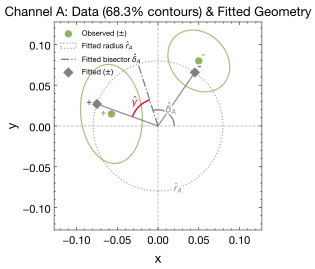

In [133]:
plot_channel('A')

#### Channel B

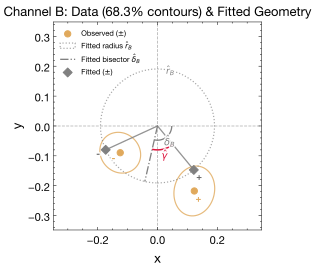

In [134]:
plot_channel('B')

#### Channel C

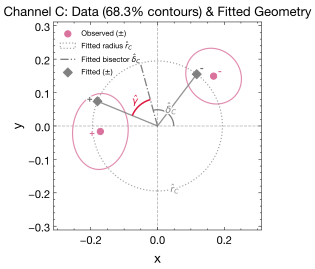

In [135]:
plot_channel('C')

In [113]:
results['1b'] = {
    "A": "results/channelA.pdf",
    "B": "results/channelB.pdf",
    "C": "results/channelC.pdf"
}

### 1c) Profile likelihood

In [10]:
# do some stuff

results['1c'] = {
    "lower": 0.0,
    "upper": 0.0
}

## **Q2** -- How well can $\gamma$ be measured?

Some (optional) markdown description

### 2a) and 2b) quoted uncertainty versus the actual spread

In [11]:
# do some stuff

fig.savefig(f"results/errors.pdf")
    
results['2'] = {
    "error_vs_k": "results/errors.pdf"
}

## **Q3** -- Does the interval cover?

Some (optional) markdown description

### 3a) measuring the coverage

In [12]:
# do some stuff

fig.savefig(f"results/coverage1.pdf")
    
results['3a'] = {
    "coverage": "results/coverage1.pdf"
}

### 3b) How is $t$ distributed?

In [13]:
# do some stuff

results['3b'] = {
    "kappas": [0.0],
    "p(T<1)": [0.0],
    "t_with_68": [0.0]
}

## **Q4** -- Is it the boundary?

Some (optional) markdown description

In [14]:
# do some stuff

## **Q5** -- A calibrated interval


In [15]:
# do some stuff

fig.savefig("results/coverage2.pdf")

results['5b'] = {
    "coverage_calib": "results/coverage2.pdf"
}

In [16]:
# save results
with open('results/results.json','w') as f:
    json.dump(results, f, indent=2)